# Permeability

Permeability, how easily fluid flows through the rock, is the hardest property to get from logs,
because logs don't measure flow. The standard workaround (Timur and its relatives) estimates it
from porosity and irreducible water saturation: more pore space and less bound water mean bigger,
better-connected pores. It captures the trend but scatters by an order of magnitude, so on its own
it's a guide, not an answer.

The fix is core. Where you have plug measurements, you fit the porosity-permeability transform to
them; this well has 200 plugs over its reservoir.

## Timur, then core

The log-only estimate is Timur's transform, permeability from porosity and irreducible water,

$$k = 0.136\,\frac{\phi^{4.4}}{S_{wirr}^{2}}$$

with $\phi$ and $S_{wirr}$ in percent and $k$ in mD. Where core plugs exist the library calibrates to them in two steps. First it ties the log porosity to the core porosity with a linear fit,

$$\phi_{corr} = A_1\,\phi_E + B_1,$$

then fits a log-linear porosity-to-permeability transform on the plugs,

$$\log_{10} k = A_2\,\phi_{corr} + B_2,$$

with the coefficients from least squares and the result capped at $10^{4}$ mD. The crossplot below compares that core-tied permeability (`PERM_CC`) against the plug measurements directly.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
REPO = Path.cwd()
while not (REPO / "petrophys").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
WELL = REPO / "petrophys" / "data" / "geolink" / "30_6-5.las"

from petrophys.io import read_las
from petrophys.workflow import run_dynamic_workflow
import numpy as np
well = read_las(WELL)
run_dynamic_workflow(well, lithology="clastic")            # computes PERM and core-tied PERM_CC
g = lambda *n: next((np.asarray(well.get(x).data, float) for x in n if well.get(x) is not None), None)
kh, perm_cc = g("KH_CORE"), g("PERM_CC")
ok = np.isfinite(kh) & np.isfinite(perm_cc) & (kh > 0) & (perm_cc > 0)
print("log10 correlation, core-tied perm vs core:",
      round(float(np.corrcoef(np.log10(perm_cc[ok]), np.log10(kh[ok]))[0, 1]), 2))

log10 correlation, core-tied perm vs core: 0.8


Permeability is always shown on a log scale because it ranges over orders of magnitude. The
core-calibrated estimate (`PERM_CC`) against the core plugs (`KH_CORE`), close to the one-to-one
line, with the scatter that's inherent to predicting flow from logs:

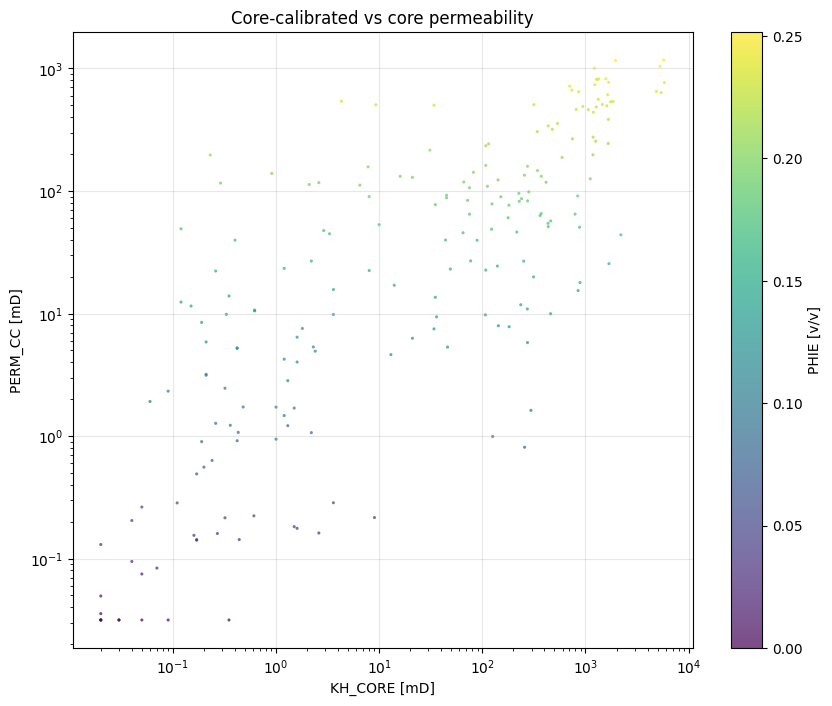

In [2]:
from petrophys.visualization import create_crossplot
create_crossplot(well, x_curve="KH_CORE", y_curve="PERM_CC", color_curve="PHIE",
                 x_log=True, y_log=True, title="Core-calibrated vs core permeability");

Treat log permeability as a calibrated estimate, not a measurement: good for ranking zones and
flagging flow units, but tie it to core before quoting absolute numbers.